# Assignment 4
Due Oct. 7

Yazdan Zinati 
260928077   

Dataset with brain atlas A for classification tasks: for the first set of 5 small programming
tasks use the Oasis dataset provided by the nilearn package, which can be downloaded
using the code below. This is a dataset of structural brain scans (aka voxel-based
morphometry) for male and female individuals.

In [1]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib

def fetch_oasis_dataset(n_rois, debug=False):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(n_rois=n_rois)
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males`

    if debug:
        print(
            "Fetched dataset.\n" "input variables shape:",
            input_variables.shape,
            "\n",
            "output variable shape",
            output_variable.shape,
            )
    return input_variables, output_variable

Task 1 - Use sklearn.linear_model.LogisticRegression(penalty=’l1’, C=1.0),
sklearn.linear_model.LogisticRegression(penalty=’l2’, C=1.0) and
sklearn.linear_model.LogisticRegression(penalty=’elasticnet’, l1_ratio=0.5,
C=1.0) to fit separate logistic predictive models based on 100, 200, 300, …, 900, 1000 brain
regions of interest (see ‘n_rois’ argument for datasets.fetch_atlas_schaefer_2018) based on
the first 80% of the 100 structural brain scans to predict sex. Next, evaluate each fitted
LogReg model on the unseen final 20% of the 100 structural brain scans and retrieve
classification accuracy in XX.YY%. Please plot the classification accuracy on the test set (x
axis=the different atlas resolutions, y axis=prediction accuracy on test set, 3 lines with 3
colors for the 3 prediction model classes with different regularization constraints).

Note: I had to change the default sklearn LR solver to:
- liblinear for l1
- saga for elasticnet

In [2]:
from sklearn.linear_model import LogisticRegression

lr1 = LogisticRegression(penalty="l1", C=1.0, solver="liblinear")
lr2 = LogisticRegression(penalty="l2", C=1.0)
lr3 = LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga")
lrs = [lr1, lr2, lr3]

num_regions = range(100, 1100, 100)
scores = [[], [], []]
zero_counts = [[], [], []]
for n_rois in num_regions:
    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    for i, lr in enumerate(lrs):
        lr.fit(train_x, train_y)

        scores[i].append(lr.score(test_x, test_y))
        zero_count = np.sum(lr.coef_ == 0)
        zero_counts[i].append(zero_count)

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:349: C

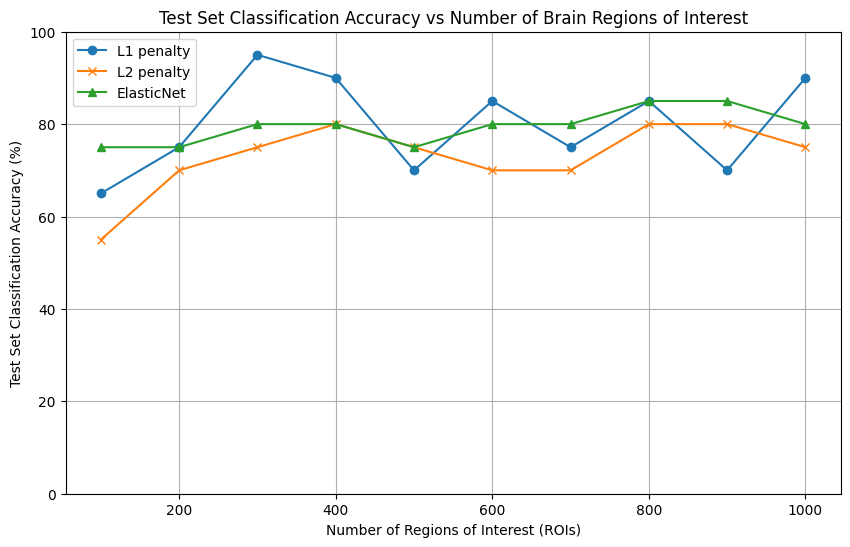

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(list(num_regions), np.array(scores[0]) * 100, marker='o', label="L1 penalty")
plt.plot(list(num_regions), np.array(scores[1]) * 100, marker='x', label="L2 penalty")
plt.plot(list(num_regions), np.array(scores[2]) * 100, marker='^', label="ElasticNet")

plt.title('Test Set Classification Accuracy vs Number of Brain Regions of Interest')
plt.xlabel('Number of Regions of Interest (ROIs)')
plt.ylabel('Test Set Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()

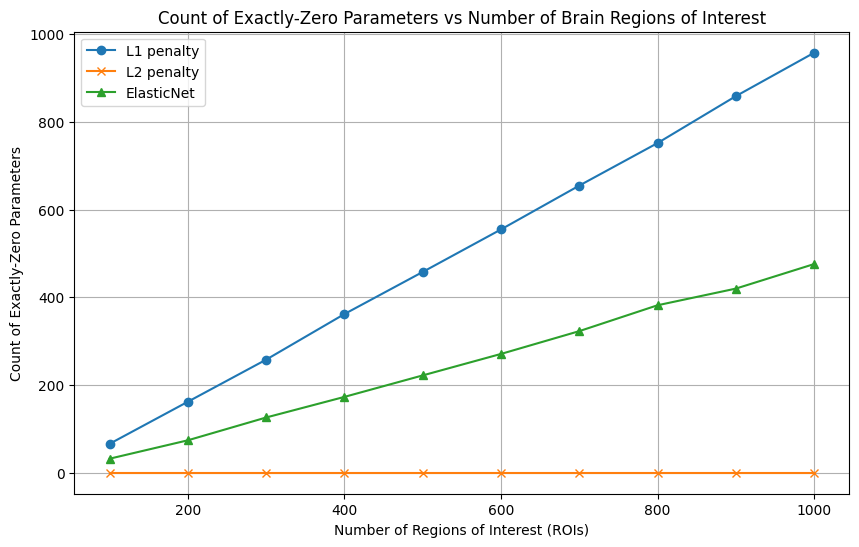

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(list(num_regions), np.array(zero_counts[0]), marker='o', label="L1 penalty")
plt.plot(list(num_regions), np.array(zero_counts[1]), marker='x', label="L2 penalty")
plt.plot(list(num_regions), np.array(zero_counts[2]), marker='^', label="ElasticNet")

plt.title('Count of Exactly-Zero Parameters vs Number of Brain Regions of Interest')
plt.xlabel('Number of Regions of Interest (ROIs)')
plt.ylabel('Count of Exactly-Zero Parameters')
plt.grid(True)
plt.legend()
plt.show()

Task 3 - The goal is to plot a ‘regularization path’ for a given classification problem. Use
sklearn.linear_model.LogisticRegression(penalty=’l1’) to fit separate logistic
predictive models based on max 1000 brain regions of interest (see ‘n_rois’ argument)
based on the first 80% of the 100 structural brain scans to predict sex differences. Find a
grid of 10 different values for the hyperparameter C, and fit a different LogReg model for
each of these choices of C. Then plot the model parameter set with different colors
(analogous to the regularization paths that were presented in the lecture, hyperparameter
choice (C) on x axis, model parameter value on y axis), such that the extremes of this grid
of increasing C values has all parameter in the model versus none of the parameters in the
model. Called ‘regularization path’.

In [5]:
Cs = np.logspace(-1.5, 7, 10)  
coefs = []


input_variables, output_variable = fetch_oasis_dataset(1000)
train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

for C in Cs:
    lr = LogisticRegression(penalty="l1", C=C, solver="liblinear")
    lr.fit(train_x, train_y)
    coefs.append(lr.coef_.flatten())


coefs = np.array(coefs).T


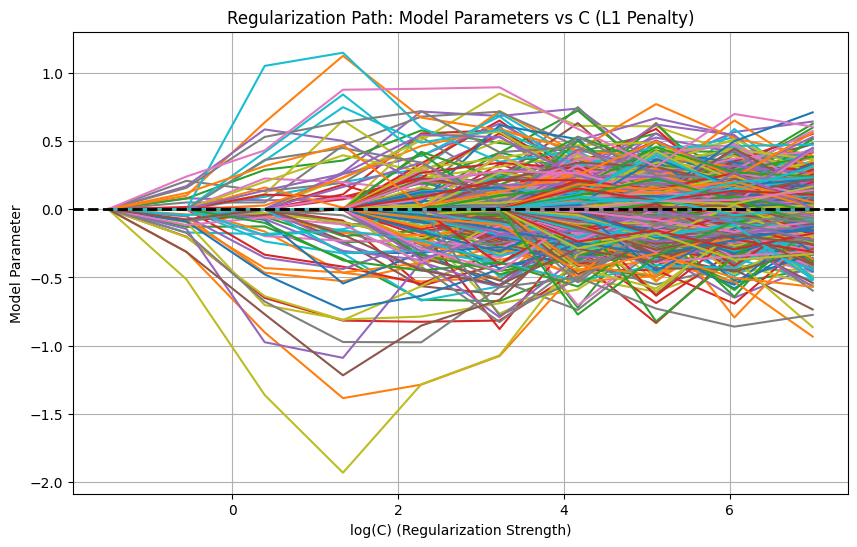

In [6]:
plt.figure(figsize=(10, 6))

for i in range(coefs.shape[0]):
    plt.plot(np.log10(Cs), coefs[i], label=f'Feature {i+1}')

plt.axhline(0, color='black', linestyle='--', linewidth=2)  # Reference line for zero

plt.title("Regularization Path: Model Parameters vs C (L1 Penalty)")
plt.xlabel("log(C) (Regularization Strength)")
plt.ylabel("Model Parameter")
plt.grid(True)
plt.show()


In [7]:
# check that C extremities have 0 and all params non zero
assert np.count_nonzero(coefs.T[-1]) == 1000
assert (np.sum(coefs.T[0]) == 0)

Task 4 - Use sklearn.linear_model.LogisticRegression(penalty=’l1’, C=1.0)
to fit separate sparse logistic predictive models based on 1000 brain regions of interest
(see ‘n_rois’ argument) based on the first 80% of the 100 structural brain scans to predict
sex differences. This previous step should be done based on 100 bootstrapping
datasets, drawing with replacement from the 80% training data. Please plot the occurrence
of non-zero model parameters across the 100 bootstrapped sparse predictive models (x
axis=the 1000 parameters related to input variables, y axis=0..100 of how many times the
fitted model had a given parameter set to a value != 0).

In [8]:
from sklearn.utils import resample


lr = LogisticRegression(penalty="l1", C=1.0, solver="liblinear")

non_zero_counts = np.zeros(1000)
n_boostrap = 100
for i in range(n_boostrap):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(train_x, train_y)
    lr.fit(input_vars_bootstrap, output_vars_bootstrap)
    non_zero_counts += (lr.coef_.flatten() != 0)


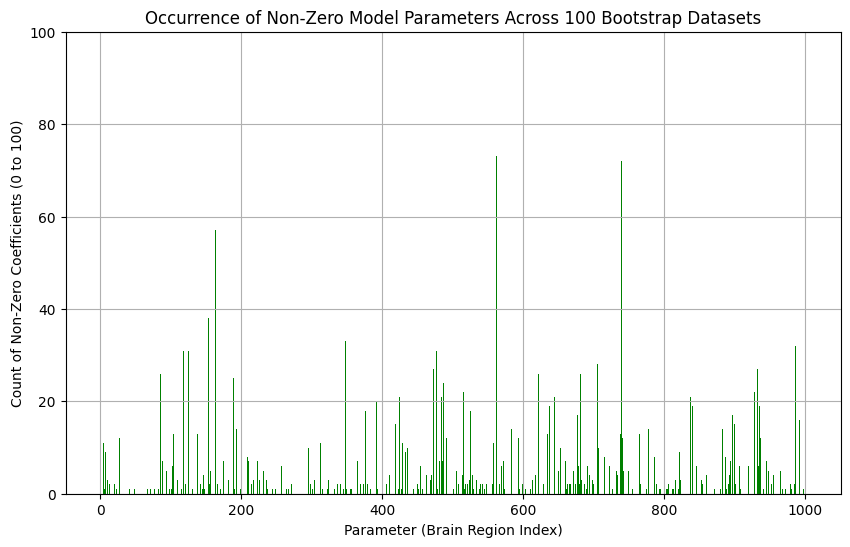

In [9]:
plt.figure(figsize=(10, 6))
plt.bar(range(1, n_rois+1), non_zero_counts, color='green')
plt.title("Occurrence of Non-Zero Model Parameters Across 100 Bootstrap Datasets")
plt.xlabel("Parameter (Brain Region Index)")
plt.ylabel("Count of Non-Zero Coefficients (0 to 100)")
plt.grid(True)
plt.ylim([0, 100])
plt.show()


Task 5 - Same as task 4, but adding noise to input data. After drawing one of the 100
bootstrap datasets and before fitting the predictive model: add random by adding to the
input data matrix the noise output from np.random.randn(80, 1000) * 0.1. Before looping
over the 100 bootstrap datasets, make sure to set random seed once via
np.random.seed(0).

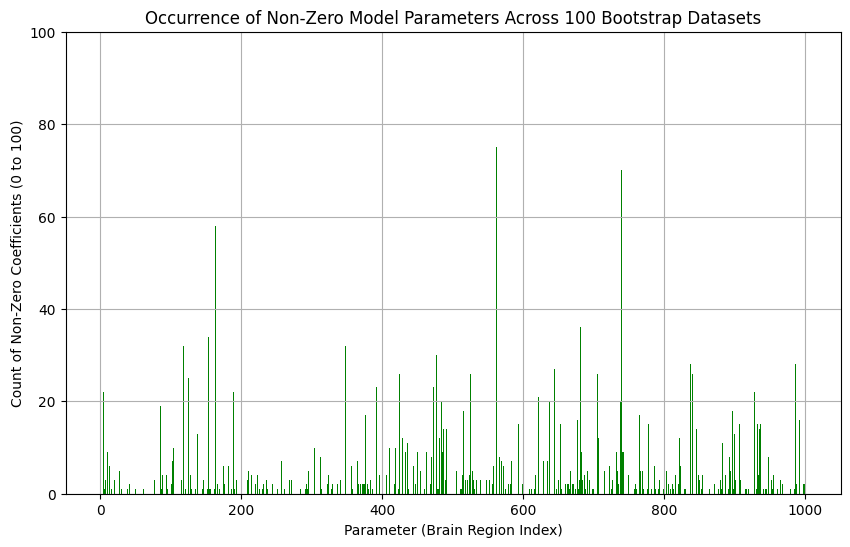

In [10]:
np.random.seed(0)
lr = LogisticRegression(penalty="l1", C=1.0, solver="liblinear")

non_zero_counts = np.zeros(1000)
n_boostrap = 100

noise_mtx = np.random.randn(80, 1000) * 0.1
for i in range(n_boostrap):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(train_x, train_y)
    noisy_input = input_vars_bootstrap + noise_mtx
    lr.fit(noisy_input, output_vars_bootstrap)
    non_zero_counts += (lr.coef_.flatten() != 0)

plt.figure(figsize=(10, 6))
plt.bar(range(1, n_rois+1), non_zero_counts, color='green')
plt.title("Occurrence of Non-Zero Model Parameters Across 100 Bootstrap Datasets")
plt.xlabel("Parameter (Brain Region Index)")
plt.ylabel("Count of Non-Zero Coefficients (0 to 100)")
plt.grid(True)
plt.ylim([0, 100])
plt.show()


Dataset with brain atlas B for continous prediction tasks: For the second set of 5 small
programming tasks use the Oasis dataset provided by the nilearn package, which can be
downloaded using the code below. This is a dataset of structural brain scans (aka voxel-
based morphometry) for male and female individuals.

In [1]:
import os 
def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        'scorr_mean': os.path.join(base_path, 'scorr05_mean_all.nii.gz'),
        'tcorr_mean': os.path.join(base_path, 'tcorr05_mean_all.nii.gz'),
        'scorr_2level': os.path.join(base_path, 'scorr05_2level_all.nii.gz'),
        'tcorr_2level': os.path.join(base_path, 'tcorr05_2level_all.nii.gz'),
        'random': os.path.join(base_path, 'random_all.nii.gz'),
        'description': 'Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.'
    }
    return craddock_data

In [2]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
from sklearn.preprocessing import StandardScaler
import nibabel as nib


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(
        crad["scorr_mean"], n_rois
    )  # this needs to be modified for some tasks
    print(
        "%i regions found in this atlas"
        % (len(np.unique(atlas_nii.get_fdata().ravel())) - 1)
    )
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring

    return input_variables, output_variable

Note: For these tasks, instead of LogisticRegression() use the three regressors Ridge(),
Lasso(), and ElasticNet(), depending on which penalty is desired. Use R2 coefficient of
determination instead of classification accuracy, which can be found at
sklearn.metrics.r2_score.

6- analogous to task 1, but predicting continuous subject age and using 43 different
versions of Craddock region atlas resolutions (.scorr_mean) instead of the 10 region
numbers from Dataset A. Use alpha=0.1.

In [3]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

versions = range(0, 43)


lr1 = Ridge(alpha=0.1)
lr2 = Lasso(alpha=0.1)
lr3 = ElasticNet(alpha=0.1)
lrs = [lr1, lr2, lr3]

scores = [[], [], []]
zero_counts = [[], [], []]
for version in versions:
    input_variables, output_variable = fetch_second_dataset(version)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    for i, lr in enumerate(lrs):
        lr.fit(train_x, train_y)

        scores[i].append(r2_score(test_y, lr.predict(test_x)))
        zero_count = np.sum(lr.coef_ == 0)
        zero_counts[i].append(zero_count)

10 regions found in this atlas
20 regions found in this atlas
30 regions found in this atlas
40 regions found in this atlas
50 regions found in this atlas
60 regions found in this atlas
70 regions found in this atlas
80 regions found in this atlas
90 regions found in this atlas
99 regions found in this atlas
106 regions found in this atlas
119 regions found in this atlas
128 regions found in this atlas
138 regions found in this atlas
147 regions found in this atlas
157 regions found in this atlas
169 regions found in this atlas
176 regions found in this atlas
185 regions found in this atlas
195 regions found in this atlas
205 regions found in this atlas
210 regions found in this atlas
220 regions found in this atlas
225 regions found in this atlas
233 regions found in this atlas
249 regions found in this atlas
258 regions found in this atlas
265 regions found in this atlas
271 regions found in this atlas
274 regions found in this atlas
319 regions found in this atlas
356 regions found 

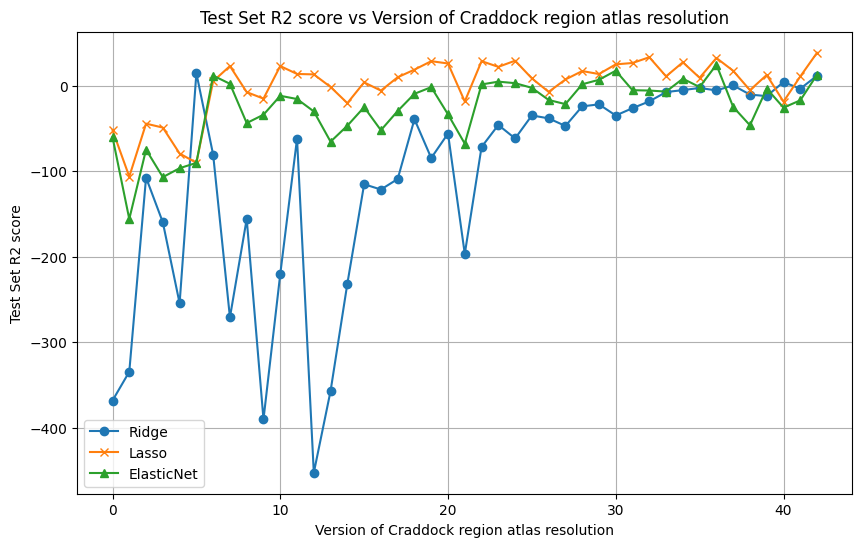

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(list(versions), np.array(scores[0]) * 100, marker='o', label="Ridge")
plt.plot(list(versions), np.array(scores[1]) * 100, marker='x', label="Lasso")
plt.plot(list(versions), np.array(scores[2]) * 100, marker='^', label="ElasticNet")

plt.title('Test Set R2 score vs Version of Craddock region atlas resolution')
plt.xlabel('Version of Craddock region atlas resolution')
plt.ylabel('Test Set R2 score')
plt.grid(True)
plt.legend()
plt.show()

7- analogous to task 2, but predicting continuous subject age and using 43 different
versions of Craddock region atlas resolutions (.scorr_mean) instead of the 10 region
numbers from Dataset A. Use alpha=0.1.

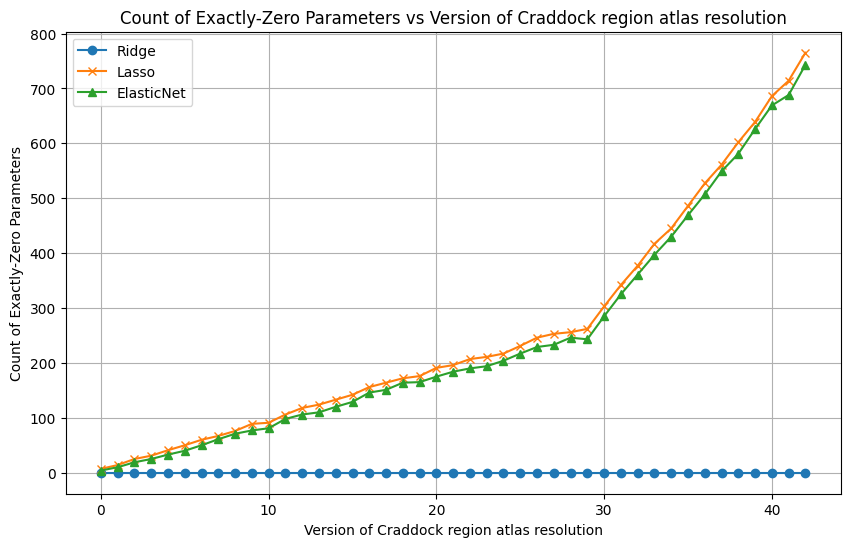

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(list(versions), np.array(zero_counts[0]), marker='o', label="Ridge")
plt.plot(list(versions), np.array(zero_counts[1]), marker='x', label="Lasso")
plt.plot(list(versions), np.array(zero_counts[2]), marker='^', label="ElasticNet")

plt.title('Count of Exactly-Zero Parameters vs Version of Craddock region atlas resolution')
plt.xlabel('Version of Craddock region atlas resolution')
plt.ylabel('Count of Exactly-Zero Parameters')
plt.grid(True)
plt.legend()
plt.show()

8- analogous to task 3, but predicting continuous subject age and using the largest (43rd,
788 input variables) of Craddock region atlas resolutions (.scorr_mean).

In [42]:
Cs = np.logspace(-6, 0.1, 10)  
coefs = []


input_variables, output_variable = fetch_second_dataset(42)
train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

for C in Cs:
    lr = Lasso(alpha=C)
    lr.fit(train_x, train_y)
    coefs.append(lr.coef_.flatten())


coefs = np.array(coefs).T


788 regions found in this atlas


/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.434e-02, tolerance: 7.709e-03
  model = cd_fast.enet_coordinate_descent(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.744e-02, tolerance: 7.709e-03
  model = cd_fast.enet_coordinate_descent(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments

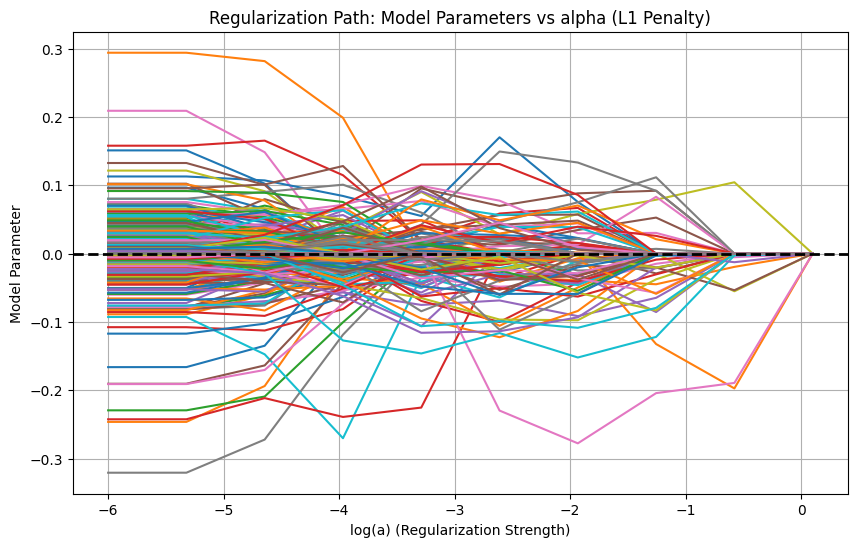

In [43]:
plt.figure(figsize=(10, 6))

for i in range(coefs.shape[0]):
    plt.plot(np.log10(Cs), coefs[i], label=f'Feature {i+1}')
plt.axhline(0, color='black', linestyle='--', linewidth=2)  # Reference line for zero

plt.title("Regularization Path: Model Parameters vs alpha (L1 Penalty)")
plt.xlabel("log(a) (Regularization Strength)")
plt.ylabel("Model Parameter")
plt.grid(True)
plt.show()


In [45]:
# check that C extremities have 0 and all params non zero
assert np.count_nonzero(coefs.T[-1]) == 0
assert np.count_nonzero(coefs.T[0]) == 788

9- analogous to task 4, but predicting continuous subject age and using the largest (43rd,
788 input variables) of Craddock region atlas resolutions (.scorr_mean). Use alpha=0.1.

In [34]:
from sklearn.utils import resample


lr = Lasso(alpha=0.1)

non_zero_counts = np.zeros(input_variables.shape[1])
n_boostrap = 100
for i in range(n_boostrap):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(train_x, train_y)
    lr.fit(input_vars_bootstrap, output_vars_bootstrap)
    non_zero_counts += (lr.coef_.flatten() != 0)


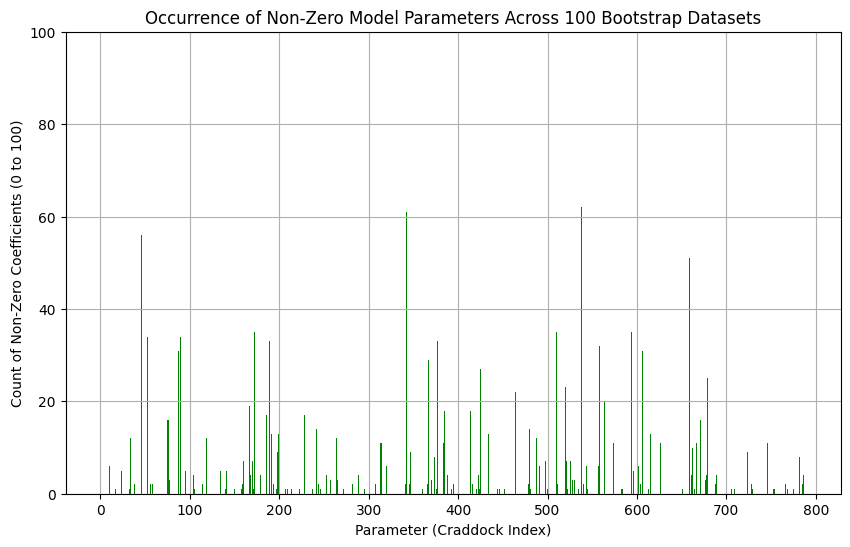

In [37]:
plt.figure(figsize=(10, 6))
plt.bar(range(1, input_variables.shape[1] + 1), non_zero_counts, color='green')
plt.title("Occurrence of Non-Zero Model Parameters Across 100 Bootstrap Datasets")
plt.xlabel("Parameter (Craddock Index)")
plt.ylabel("Count of Non-Zero Coefficients (0 to 100)")
plt.grid(True)
plt.ylim([0, 100])
plt.show()

10- analogous to task 5, but predicting continuous subject age and using the largest (43rd,
788 input variables) of Craddock region atlas resolutions (.scorr_mean) instead of the 10
region numbers from Dataset A. Use alpha=0.1.

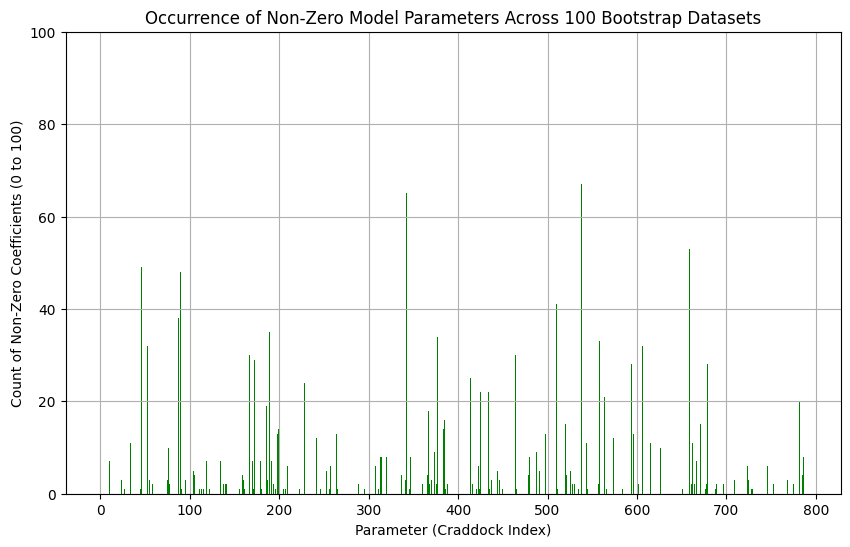

In [41]:
np.random.seed(0)
lr = Lasso(alpha=0.1)

non_zero_counts = np.zeros(input_variables.shape[1])
n_boostrap = 100

noise_mtx = np.random.randn(80, input_variables.shape[1]) * 0.1
for i in range(n_boostrap):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(train_x, train_y)
    noisy_input = input_vars_bootstrap + noise_mtx
    lr.fit(noisy_input, output_vars_bootstrap)
    non_zero_counts += (lr.coef_.flatten() != 0)

plt.figure(figsize=(10, 6))
plt.bar(range(1, input_variables.shape[1]+ 1), non_zero_counts, color='green')
plt.title("Occurrence of Non-Zero Model Parameters Across 100 Bootstrap Datasets")
plt.xlabel("Parameter (Craddock Index)")
plt.ylabel("Count of Non-Zero Coefficients (0 to 100)")
plt.grid(True)
plt.ylim([0, 100])
plt.show()